# **EDA: Credit Card Transactions Fraud Detection**

In [71]:
import os
import warnings
import pandas as pd
import numpy as np
import math
from matplotlib import pyplot as plt
import kagglehub
from kagglehub import KaggleDatasetAdapter
import seaborn as sns

np.random.seed(42)
warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 100)
pd.set_option('display.width', 1000)

data_path = kagglehub.dataset_download("kartik2112/fraud-detection")
train_path = os.path.join(data_path, "fraudTrain.csv")

dfTrain = pd.read_csv(train_path)
X = dfTrain.drop(columns=["is_fraud"])
y = dfTrain["is_fraud"]

Using Colab cache for faster access to the 'fraud-detection' dataset.


# Описание датасета

In [72]:
print('Размерность train датасета:', X.shape)
print('='*100)
print(f'Пример данных:\n{'='*100}\n', X.head(20))
X.info()

Размерность train датасета: (1296675, 22)
Пример данных:
     Unnamed: 0 trans_date_trans_time               cc_num                                  merchant       category     amt        first       last gender                          street                      city state    zip      lat      long  city_pop                                            job         dob                         trans_num   unix_time  merch_lat  merch_long
0            0   2019-01-01 00:00:18     2703186189652095                fraud_Rippin, Kub and Mann       misc_net    4.97     Jennifer      Banks      F                  561 Perry Cove            Moravian Falls    NC  28654  36.0788  -81.1781      3495                      Psychologist, counselling  1988-03-09  0b242abb623afc578575680df30655b9  1325376018  36.011293  -82.048315
1            1   2019-01-01 00:00:44         630423337322           fraud_Heller, Gutmann and Zieme    grocery_pos  107.23    Stephanie       Gill      F    43039 Riley Greens Su

---
Описание полей и единиц измерения датасета **X**:
- Unnamed: 0 — технический порядковый индекс строки из исходного файла.
- trans_date_trans_time — дата и точное время совершения транзакции (YYYY-MM-DD HH:MM:SS).
- cc_num — уникальный номер кредитной карты клиента.
- merchant — название торговой точки или сервиса, принявшего оплату.
- category — категория покупки (grocery_pos, shopping_net, travel и т. д.).
- amt — сумма транзакции в долларах США ($).
- first — имя держателя карты.
- last — фамилия держателя карты.
- gender — пол держателя карты (M — мужской, F — женский).
- street — улица проживания клиента.
- city — город проживания клиента.
- state — двухбуквенный код штата США, где проживает клиент.
- zip — почтовый индекс клиента.
- lat — географическая широта адреса клиента.
- long — географическая долгота адреса клиента.
- city_pop — численность населения города клиента.
- job — профессия держателя карты.
- dob — дата рождения держателя карты (YYYY-MM-DD).
- trans_num — уникальный буквенно-цифровой идентификатор транзакции.
- unix_time — время совершения транзакции в формате Unix Timestamp (секунды с 1 января 1970 года).
- merch_lat — географическая широта торговой точки (мерчанта).
- merch_long — географическая долгота торговой точки (мерчанта).
---
Целевой признак вынесен в отдельный датасет **y**:
- is_fraud — целевой признак (1 — мошенническая транзакция, 0 — обычная операция).



# Аудит структуры и качества

Вывод количественных характеристик, выбросов, масштабов признаков.

In [73]:
df_eda = X.copy()
df_eda['is_fraud'] = y

dt = pd.to_datetime(df_eda['trans_date_trans_time'])
dob = pd.to_datetime(df_eda['dob'], errors='coerce')

df_eda['hour'] = dt.dt.hour
df_eda['dow'] = dt.dt.dayofweek
df_eda['month'] = dt.dt.month
df_eda['is_weekend'] = df_eda['dow'].isin([5, 6]).astype(int)
df_eda['age'] = ((dt.dt.normalize() - dob).dt.days / 365.2425).clip(0, 120)
df_eda['log_amt'] = np.log1p(df_eda['amt'].clip(lower=0))

lat1, lon1 = np.radians(df_eda['lat']), np.radians(df_eda['long'])
lat2, lon2 = np.radians(df_eda['merch_lat']), np.radians(df_eda['merch_long'])
dlat, dlon = lat2 - lat1, lon2 - lon1
a = np.sin(dlat / 2)**2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlon / 2)**2
df_eda['distance_km'] = 6371.0 * 2 * np.arcsin(np.sqrt(a.clip(0, 1)))

num_cols = [
    "amt", "lat", "long", "city_pop", "merch_lat", "merch_long",
    "hour", "dow", "month", "is_weekend", "age", "log_amt", "distance_km"
]

print("Статистика только по осмысленным числовым признакам:")
display(df_eda[num_cols].describe().T.round(2))

print("="*100)

print("Отдельная статистика по категориальным полям:")
display(X.describe(include=["object"]).T)

Статистика только по осмысленным числовым признакам:


,count,mean,std,min,25%,50%,75%,max
amt,1296675.0,70.35,160.32,1.00,9.65,47.52,83.14,28948.90
lat,1296675.0,38.54,5.08,20.03,34.62,39.35,41.94,66.69
long,1296675.0,-90.23,13.76,-165.67,-96.80,-87.48,-80.16,-67.95
city_pop,1296675.0,88824.44,301956.36,23.00,743.00,2456.00,20328.00,2906700.00
merch_lat,1296675.0,38.54,5.11,19.03,34.73,39.37,41.96,67.51
merch_long,1296675.0,-90.23,13.77,-166.67,-96.90,-87.44,-80.24,-66.95
hour,1296675.0,12.80,6.82,0.00,7.00,14.00,19.00,23.00
dow,1296675.0,3.07,2.20,0.00,1.00,3.00,5.00,6.00
month,1296675.0,6.14,3.42,1.00,3.00,6.00,9.00,12.00
is_weekend,1296675.0,0.35,0.48,0.00,0.00,0.00,1.00,1.00


Отдельная статистика по категориальным полям:


,count,unique,top,freq
trans_date_trans_time,1296675,1274791,2019-04-22 16:02:01,4
merchant,1296675,693,fraud_Kilback LLC,4403
category,1296675,14,gas_transport,131659
first,1296675,352,Christopher,26669
last,1296675,481,Smith,28794
gender,1296675,2,F,709863
street,1296675,983,864 Reynolds Plains,3123
city,1296675,894,Birmingham,5617
state,1296675,51,TX,94876
job,1296675,494,Film/video editor,9779


### Промежуточный результат на данных тренировочного датасета
1. В данных полностью отсутствуют пропуски.
2. Сильный перекос в суммах по транзакциям и количестве населения.
3. Средние и квантили координат клиентов и торговых точек почти одинаковы. Но как идею можно попробовать посчитать расстояние от предыдущей покупки по той же карте. Если отсортировать транзакции по номеру карты и времени, а затем посчитать дистанцию между текущей точкой продаж и предыдущей, то используя время между транзакциями можно посчитать скорость перемещения покупателя. Резкие скачки за пару минут будут теоретически нашими целями.
4. Низкая уникальность first, last, street или dob. Использовать эти признаки может оказаться опасным: можно получить переобучение.
5. Поля Unnamed и trans_num уникальны и в них нет ценной информации.
6. Кардинальность категориальных полей category и gender низкая. Их можно закодировать через One-Hot Encoding.
7. Кардинальность полей merchant, job и city высокая. Эти категориальные данные нужно использовать, но предварительно закодировать частотой.
8. Признаки строятся только из информации, доступной на момент транзакции. Имя, адрес, номер карты и trans_num не желательно использовать как обычные категориальные признаки, которые могут стать причиной переобучения.

## Целевая переменная

,Количество,"Доля, %"
is_fraud,,
0,1289169,99.42%
1,7506,0.58%


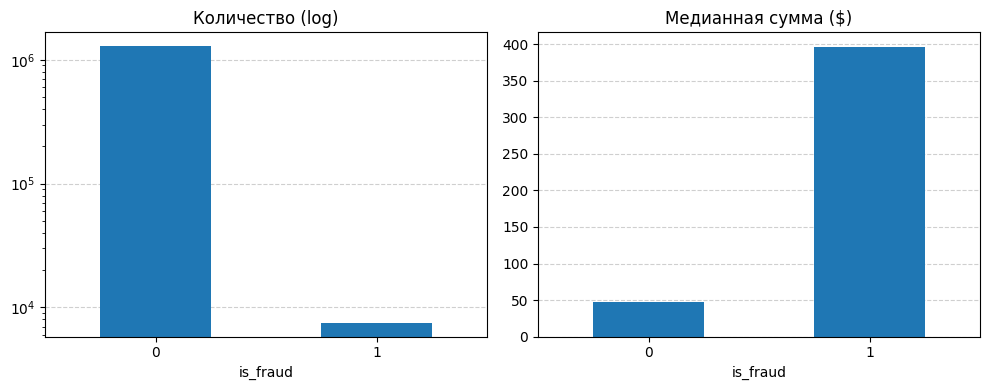

In [74]:
def target_summary(s):
    out = s.value_counts(dropna=False).to_frame("Количество")
    out["Доля, %"] = (out["Количество"] / len(s) * 100).round(2).astype(str) + "%"
    display(out)

target_summary(y)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

y.value_counts().plot(kind='bar', ax=axes[0], logy=True, title="Количество (log)")
df_eda.groupby('is_fraud')['amt'].median().plot(kind='bar', ax=axes[1], title="Медианная сумма ($)")

for ax in axes:
    ax.grid(axis='y', linestyle='--', alpha=0.6)
    ax.set_axisbelow(True)
    ax.tick_params(axis='x', rotation=0)

plt.tight_layout()
plt.show()

### Промежуточный результат в разрезе целевой переменной
Целевая переменная is_fraud характеризуется сильным перекосом классов в разрезе количества мошеннеческих операций и в разрезе медианной суммы чека.
1. Аномальные выбросы по факту могут оказаться подозрительной операцией: мошенники стремятся вывести крупные суммы за минимальное число транзакций до блокировки карты, что делает amt слишком очевидным признаком. Поэтому полагаться **только** на него нельзя.
2. Необходимо будет выполнять балансировку. При обучении алгоритмов, возможно, потребуется задавать веса классов чтобы модель не игнорировала редкий класс.
3. При оценке подумать о таких показателях как Recall (какую долю всех мошенников удалось поймать), Precision (какая доля заблокированных операций реально оказалась фродом) и PR-AUC (их общий баланс).

##Ошибочные значения

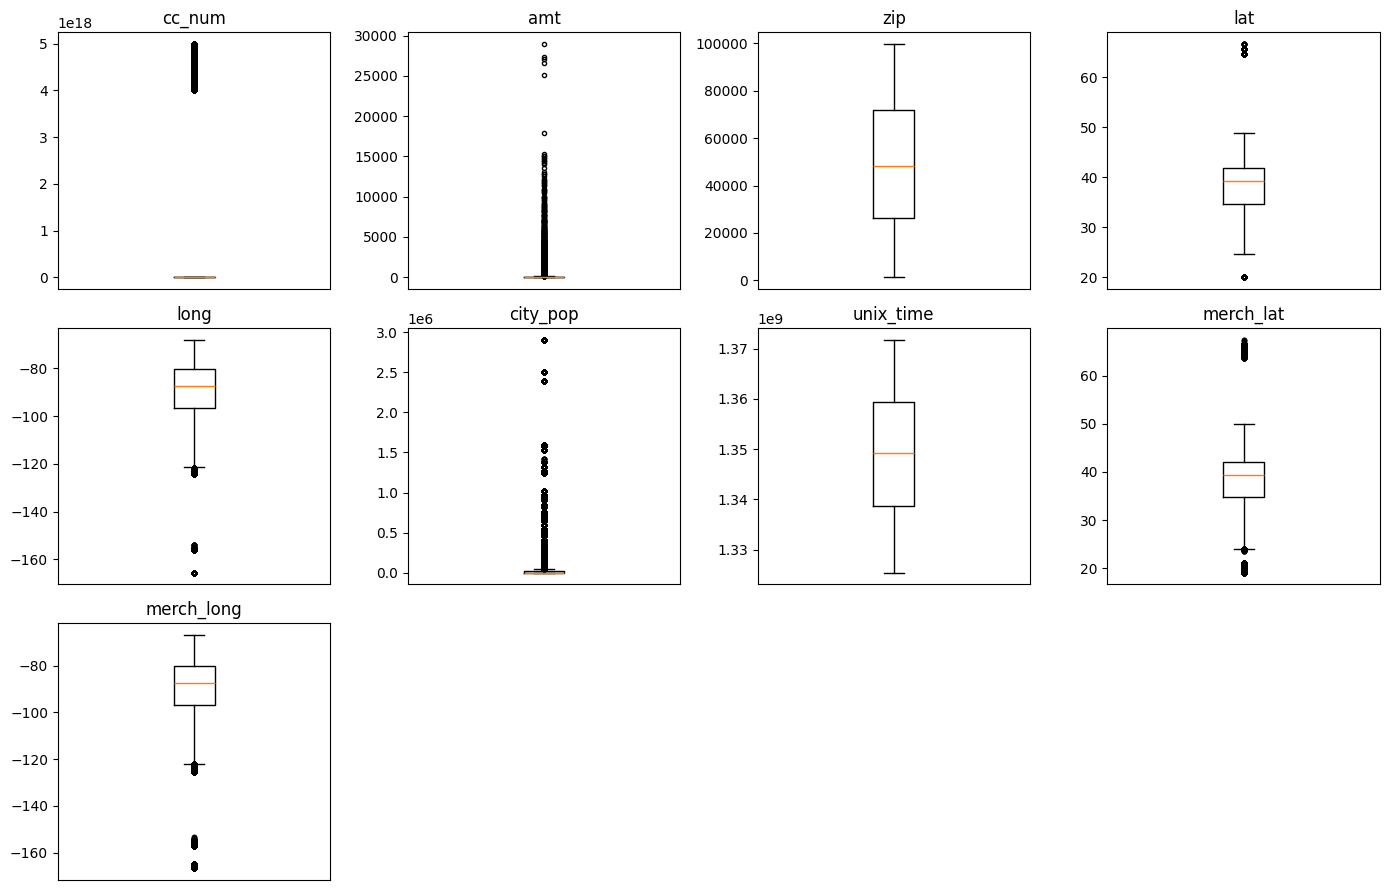

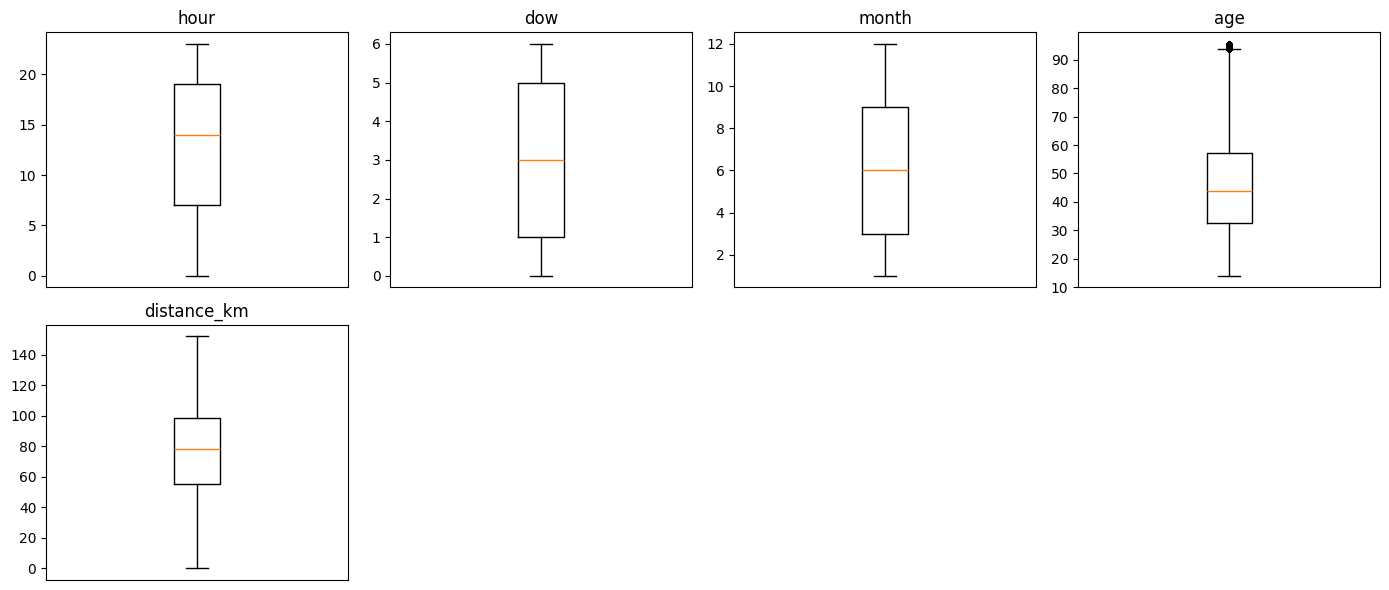

In [75]:
def plot_boxplots(df, cols, ncols=4):
    nrows = math.ceil(len(cols) / ncols)
    fig = plt.figure(figsize=(ncols * 3.5, nrows * 3))
    for i, col in enumerate(cols, start=1):
        ax = fig.add_subplot(nrows, ncols, i)
        ax.boxplot(df[col].dropna(), sym='.')
        ax.set_title(col)
        ax.set_xticks([])
    plt.tight_layout()
    plt.show()

plot_cols = ["cc_num", "amt", "zip", "lat", "long", "city_pop", "unix_time", "merch_lat", "merch_long"]
plot_cols_advanced = ["hour", "dow", "month", "age", "distance_km"]

plot_boxplots(X, plot_cols)
plot_boxplots(df_eda, plot_cols_advanced)

###Промежуточный результат
Грубых технических сбоев и вылетов за физические границы не нашел.

#Анализ взаимосвязей фрода с характеристиками транзакций

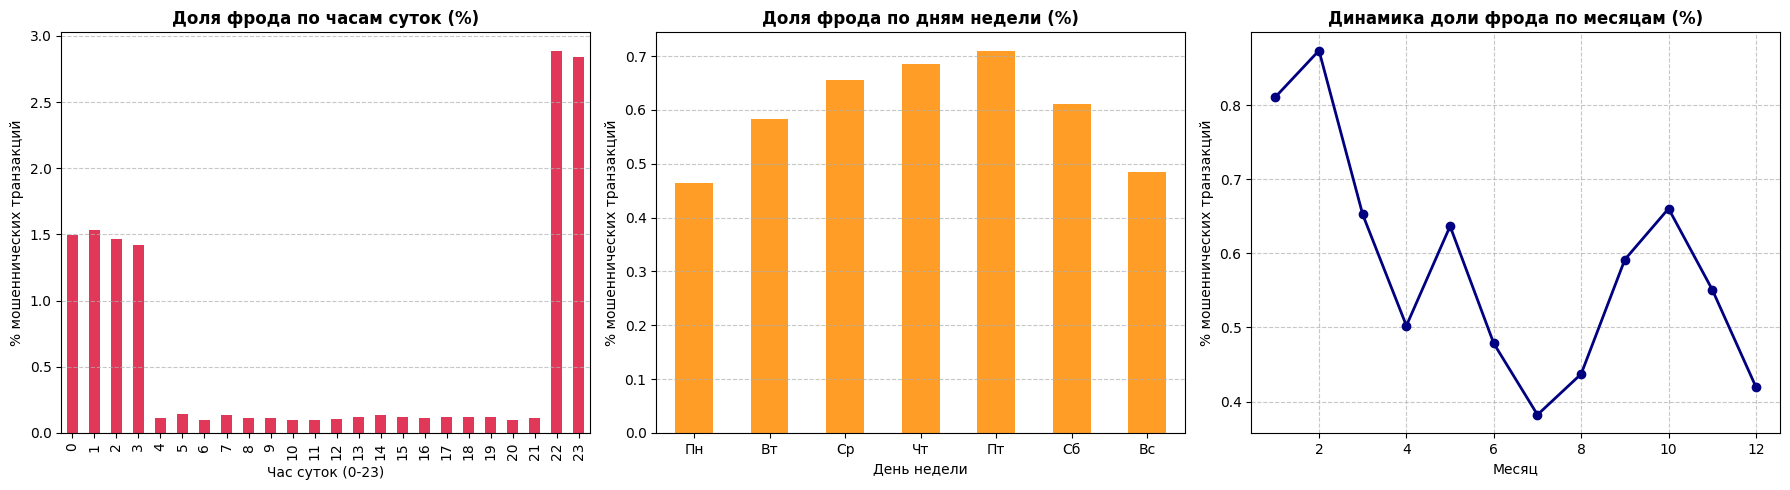

Доля фрода в ночное время (22:00 - 05:59): 1.66%
Доля фрода в дневное время (06:00 - 21:59): 0.11%


In [76]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

plots = [
    ('hour', 'bar', 'Доля фрода по часам суток (%)', 'Час суток (0-23)', {'color': 'crimson', 'alpha': 0.85}),
    ('dow', 'bar', 'Доля фрода по дням недели (%)', 'День недели', {'color': 'darkorange', 'alpha': 0.85, 'rot': 0}),
    ('month', 'line', 'Динамика доли фрода по месяцам (%)', 'Месяц', {'color': 'navy', 'marker': 'o', 'linewidth': 2})
]

for ax, (col, kind, title, xlabel, kwargs) in zip(axes, plots):
    data = df_eda.groupby(col)['is_fraud'].mean() * 100
    if col == 'dow':
        data.index = ['Пн', 'Вт', 'Ср', 'Чт', 'Пт', 'Сб', 'Вс']
    data.plot(kind=kind, ax=ax, **kwargs)
    ax.set(title=title, xlabel=xlabel, ylabel='% мошеннических транзакций')
    ax.title.set_weight('bold')
    ax.grid(axis='both' if kind == 'line' else 'y', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

is_night = df_eda['hour'].isin([22, 23, 0, 1, 2, 3, 4, 5])
print(f"Доля фрода в ночное время (22:00 - 05:59): {df_eda[is_night]['is_fraud'].mean() * 100:.2f}%")
print(f"Доля фрода в дневное время (06:00 - 21:59): {df_eda[~is_night]['is_fraud'].mean() * 100:.2f}%")


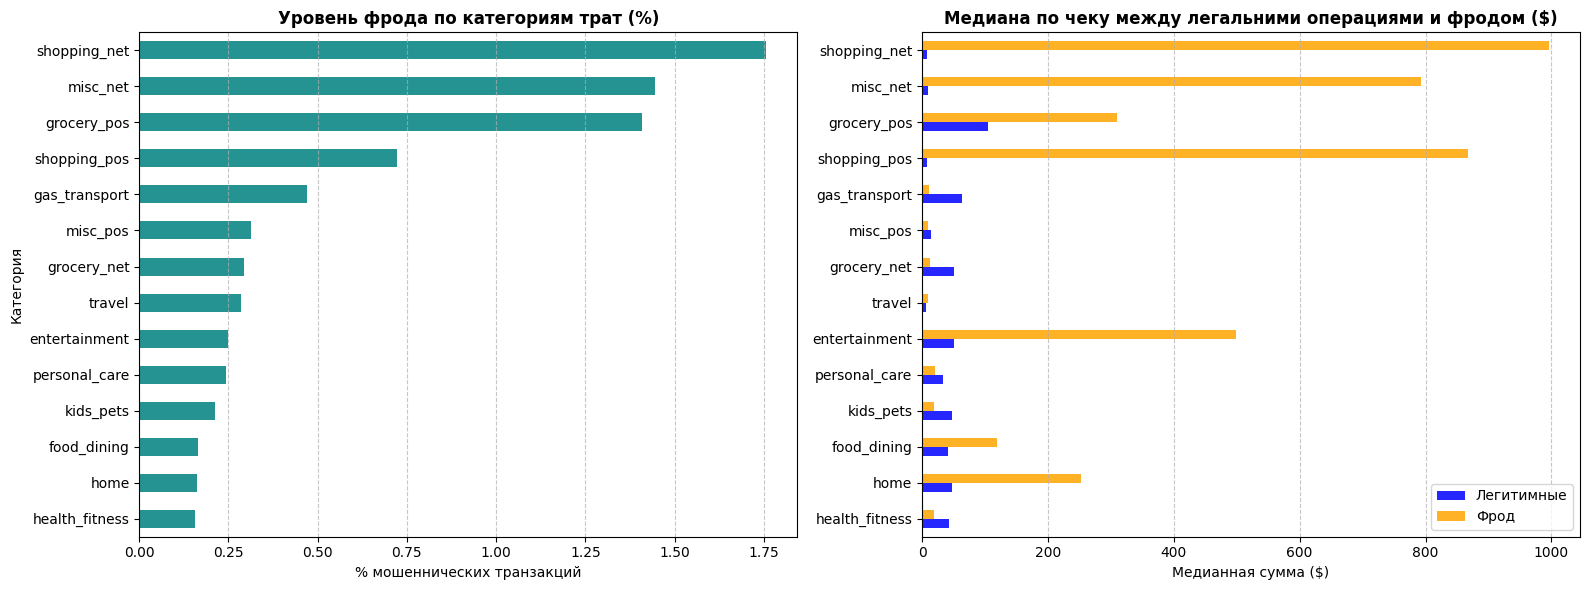

,Всего_транзакций,Фродовых_операций,Доля_фрода_процент
gender,,,
F,709863,3735,0.526
M,586812,3771,0.643


In [77]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

cat_fraud = (df_eda.groupby('category')['is_fraud'].mean() * 100).sort_values()
cat_amt = df_eda.groupby(['category', 'is_fraud'])['amt'].median().unstack().reindex(cat_fraud.index)
cat_amt.columns = ['Легитимные', 'Фрод']

plots = [
    (cat_fraud, 'Уровень фрода по категориям трат (%)', '% мошеннических транзакций', 'Категория', 'teal'),
    (cat_amt, 'Медиана по чеку между легальними операциями и фродом ($)', 'Медианная сумма ($)', '', ['blue', 'orange'])
]

for ax, (data, title, xlabel, ylabel, color) in zip(axes, plots):
    data.plot(kind='barh', ax=ax, color=color, alpha=0.85)
    ax.set(title=title, xlabel=xlabel, ylabel=ylabel)
    ax.title.set_weight('bold')
    ax.grid(axis='x', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

gender_summary = df_eda.groupby('gender')['is_fraud'].agg(
    Всего_транзакций='count',
    Фродовых_операций='sum',
    Доля_фрода_процент=lambda x: round(x.mean() * 100, 3)
)
display(gender_summary)



# Зависимость данных

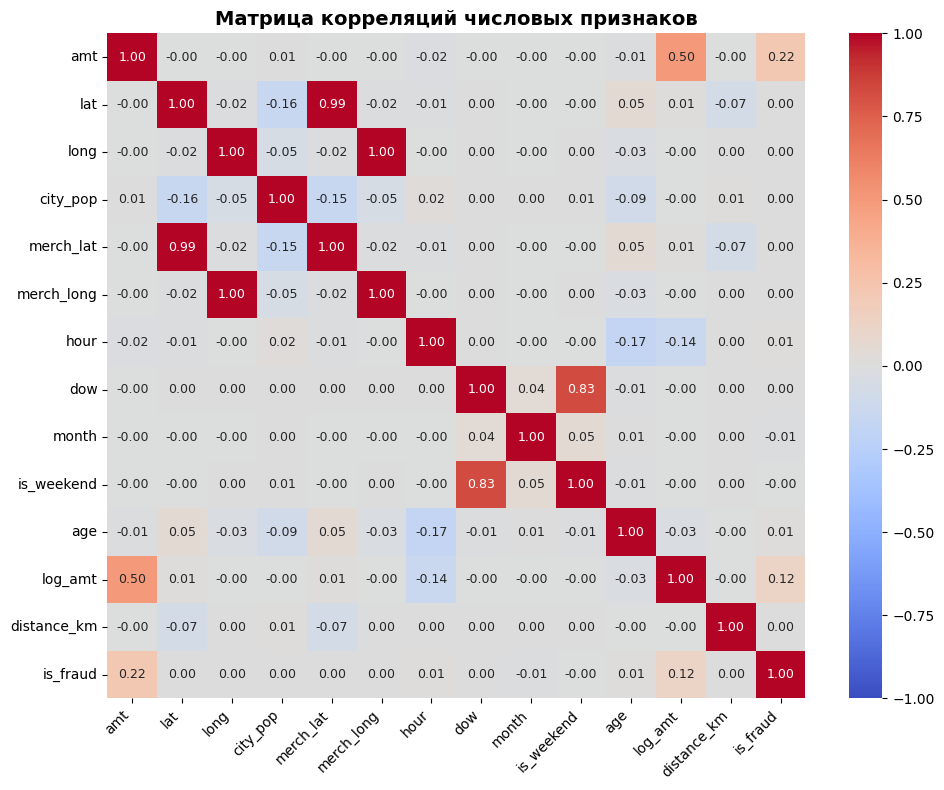

,is_fraud
is_fraud,1.0000
amt,0.2194
log_amt,0.1204
hour,0.0138
age,0.0123
city_pop,0.0021
lat,0.0019
merch_lat,0.0017
dow,0.0017
merch_long,0.0017


In [78]:
corr_matrix = df_eda[num_cols + ['is_fraud']].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, annot_kws={'size': 9})
plt.title('Матрица корреляций числовых признаков', fontsize=14, fontweight='bold')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

display(corr_matrix[['is_fraud']].sort_values(by='is_fraud', ascending=False).round(4))


#Итоговое заключение по результатам EDA


1. Большой перекос целевого класса is_fraud.
2. Временные аномалии: увеличение is_fraud в ночное время.
3. Подозрительность по категориям и транзакциям. Самый высокий риск мошенничества в категориях shopping_net, grocery_pos, misc_net и shopping_pos.
Самый низкий риск в категориях gas_transport, food_dining, health_fitness.
Средний чек у мошенников почти в 8 раз больше, чем у обычных покупателей.
Также под фрод, скореевсего, попадают серии средних покупок на 200–300 долларов или разовые крупные суммы транзакций на 800$–1000 долларов. Но это лучше еще проверить.
4. Координаты держателя карты и продавца сами по себе не имеют высокой прямой зависимости с фродом. Но скорость перемещения покупателя между двумя последовательными транзакциями может указывать на фрод. Тут я сомневаюсь в том, что такая история это норма для онлайн покупок. Надо обсудить.
5. Не использовать cc_num напрямую в качестве категории во избежание переобучения модели на конкретных пользователей обучающей выборки.